In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from functools import reduce

# 1. Definiciones

In [77]:
# Número de simulaciones
N_SIM = 30_000

# Probabilidadess
P_BASE = 0.000270243

PROB_BY_COB = {
    "Reembolso de Gastos Medicos": 0.001264099,
    "Perdidas Organicas A": 0.0000996,
    "Perdidas Organicas B": 0.00015
}

# Retención
RETENCION = 100_500_000
####3_000_000
#RETENCION = 1_500_000
##RETENCION = 100_500_000

# 2. Funciones

In [3]:
# Filtrar pólizas a considerar para la simulación

def filter_vigentes(df, fecha_corte):
    """
    Filtra pólizas vigentes a una fecha de corte.

    df: DataFrame con columnas FE_INI y F_FIN
    fecha_corte: string o datetime (ej. '2025-01-01')
    """

    df = df.copy()

    df["FE_INI"] = pd.to_datetime(df["FE_INI"])
    df["F_FIN"] = pd.to_datetime(df["F_FIN"])
    fecha_corte = pd.to_datetime(fecha_corte)

    vigentes = df[
        (df["FE_INI"] <= fecha_corte) &
        (df["F_FIN"] >= fecha_corte)
    ].reset_index(drop=True)

    return vigentes


In [4]:
# Simulación de pérdidas para la cobertura base

def simulate_losses_base(df, p_claim, retention, n_sim=100_000, seed=123):
    """
    df: DataFrame con columna 'SA'
    p_claim: probabilidad de siniestro
    retention: retención por siniestro
    """

    rng = np.random.default_rng(seed)

    n_policies = len(df)

    # 1. Simulación de siniestros
    claims = rng.binomial(
        n=1,
        p=p_claim,
        size=(n_policies, n_sim)
    )

    # 2. Severidad neta con retención
    net_sa = np.maximum(df["SA"].values - retention, 0)

    # 3. Pérdidas netas
    losses = claims * net_sa[:, None]

    # 4. DataFrame de simulaciones por póliza
    sim_cols = [f"sim_{i+1}" for i in range(n_sim)]
    losses_df = pd.DataFrame(losses, columns=sim_cols, index=df.index)

    df_out = pd.concat([df.reset_index(drop=True), losses_df], axis=1)

    # 5. Pérdida anual total
    annual_losses = losses.sum(axis=0)

    annual_losses_df = pd.DataFrame({
        "simulation": sim_cols,
        "annual_loss": annual_losses
    })

    return df_out, annual_losses_df


In [38]:
# Simulación para la cobertura principal y posteriormente las adicionales

def simulate_losses_base_1(df, retention, n_sim=100_000, seed=123):
    """
    df: Serie
    p_claim: probabilidad de siniestro
    """

    #rng = np.random.default_rng(seed)

    n_policies = len(df)


    # 2. Severidad neta con retención
    net_sa = np.maximum(df-RETENCION , 0)

    # 3. Pérdidas netas
    losses =  net_sa

    return  losses

In [40]:
def simulate_losses_adicionales_1(df, p_claim,n_sim=10_000, seed=123):
    rng = np.random.default_rng(seed)

    n_policies = len(df)

    # 1. Simulación de ocurrencia
    claims = rng.binomial(
        n=1,
        p=p_claim,
        size=(n_policies, n_sim)
    )

    # 2. Severidad con retención
    net_sa = df["SA"].values

    # 3. Pérdidas netas
    losses = claims * net_sa[:, None]

    sim_cols = [f"sim_{i+1}" for i in range(n_sim)]
    #losses_df = pd.DataFrame(losses, columns=sim_cols)

    #df_out = pd.concat([df.reset_index(drop=True), losses_df], axis=1)

    # 4. Pérdida anual agregada
    annual_losses = losses.sum(axis=0)

    annual_losses_df = pd.DataFrame({
        "simulation": sim_cols,
        "annual_loss": annual_losses
    })

    return annual_losses_df


In [41]:
np.maximum(df-RETENCION, 0)

,annual_loss
0,0
1,0
2,0
3,0
4,0
...,...
29995,0
29996,0
29997,0
29998,0


In [6]:
# Simulación de pérdidas para las coberturas adicionales

def simulate_losses_adicionales(df, p_claim, retention, n_sim=10_000, seed=123):
    rng = np.random.default_rng(seed)

    n_policies = len(df)

    # 1. Simulación de ocurrencia
    claims = rng.binomial(
        n=1,
        p=p_claim,
        size=(n_policies, n_sim)
    )

    # 2. Severidad con retención
    net_sa = np.maximum(df["SA"].values - retention, 0)

    # 3. Pérdidas netas
    losses = claims * net_sa[:, None]

    sim_cols = [f"sim_{i+1}" for i in range(n_sim)]
    losses_df = pd.DataFrame(losses, columns=sim_cols)

    df_out = pd.concat([df.reset_index(drop=True), losses_df], axis=1)

    # 4. Pérdida anual agregada
    annual_losses = losses.sum(axis=0)

    annual_losses_df = pd.DataFrame({
        "simulation": sim_cols,
        "annual_loss": annual_losses
    })

    return df_out, annual_losses_df


In [7]:
# Convergencia por simulación

def plot_convergence_mean_p99(
    losses,
    title,
    step_initial=100,
    step_late=2000,
    switch_at=5_000
):


    losses = np.asarray(losses)
    n = len(losses)

    # --- Media acumulada ---
    cum_mean = np.cumsum(losses) / np.arange(1, n + 1)

    # --- Pasos adaptativos para P99 ---
    steps = (
        list(range(step_initial, min(switch_at, n), step_initial))
        + list(range(switch_at, n + 1, step_late))
    )
    steps = [s for s in steps if s <= n]

    p99_vals = [np.quantile(losses[:i], 0.99) for i in steps]

    # --- Gráfica ---
    fig, ax1 = plt.subplots(figsize=(9, 5))

    ax1.plot(
        range(1, n + 1),
        cum_mean,
        color="tab:blue",
        label="Media acumulada"
    )
    ax1.set_xlabel("Número de simulaciones")
    ax1.set_ylabel("Media de pérdida anual", color="tab:blue")
    ax1.tick_params(axis="y", labelcolor="tab:blue")
    ax1.grid(True)

    ax2 = ax1.twinx()
    ax2.plot(
        steps,
        p99_vals,
        color="tab:red",
        linestyle="--",
        label="P99 acumulado"
    )
    ax2.set_ylabel("P99 de pérdida anual", color="tab:red")
    ax2.tick_params(axis="y", labelcolor="tab:red")

    # Leyenda combinada
    lines_1, labels_1 = ax1.get_legend_handles_labels()
    lines_2, labels_2 = ax2.get_legend_handles_labels()
    ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc="best")

    plt.title(title)
    plt.tight_layout()
    plt.show()


In [8]:
# Convergencia para las pérdidas totales

def plot_convergence_mean_p99_total(
    losses,
    title="Convergencia agregada: media y P99",
    step_initial=200,
    step_late=3000,
    switch_at=5_000
):
    losses = np.asarray(losses)
    n = len(losses)

    # Media acumulada
    cum_mean = np.cumsum(losses) / np.arange(1, n + 1)

    # Pasos adaptativos para P99
    steps = (
        list(range(step_initial, min(switch_at, n), step_initial))
        + list(range(switch_at, n + 1, step_late))
    )
    steps = [s for s in steps if s <= n]

    p99_vals = [np.quantile(losses[:i], 0.99) for i in steps]

    mean_final = losses.mean()
    p99_final = np.quantile(losses, 0.99)

    # Gráfica
    fig, ax1 = plt.subplots(figsize=(9, 5))

    ax1.plot(
        range(1, n + 1),
        cum_mean,
        color="tab:blue",
        label="Media acumulada"
    )
    ax1.axhline(
        mean_final, color="tab:blue",
        linestyle=":", alpha=0.4
    )
    ax1.set_xlabel("Número de simulaciones")
    ax1.set_ylabel("Media de pérdida anual", color="tab:blue")
    ax1.tick_params(axis="y", labelcolor="tab:blue")
    ax1.grid(True)

    ax2 = ax1.twinx()
    ax2.plot(
        steps,
        p99_vals,
        color="tab:red",
        linestyle="--",
        label="P99 acumulado"
    )
    ax2.axhline(
        p99_final, color="tab:red",
        linestyle=":", alpha=0.4
    )
    ax2.set_ylabel("P99 de pérdida anual", color="tab:red")
    ax2.tick_params(axis="y", labelcolor="tab:red")

    # Leyenda combinada
    lines_1, labels_1 = ax1.get_legend_handles_labels()
    lines_2, labels_2 = ax2.get_legend_handles_labels()
    ax1.legend(
        lines_1 + lines_2,
        labels_1 + labels_2,
        loc="best"
    )

    plt.title(title)
    plt.tight_layout()
    plt.show()


# 2. Datos

In [42]:
INPUT_FILE = "./Suma Asegurada AP Vigor.xlsx"

In [43]:
cobertura_base = pd.read_excel(INPUT_FILE, sheet_name="Sheet1")
coberturas_adicionales = pd.read_excel(INPUT_FILE, sheet_name="Sheet2")

## **Simulaciones**


In [78]:
#Se simula la cobertura basica
base_sim_1 = simulate_losses_adicionales_1(
    cobertura_base,
    p_claim=P_BASE,
    n_sim=N_SIM,
    seed=2024
)

In [79]:
#Se revisan las coberturas adicionales
coberturas_adicionales["COB"].unique()

array(['Reembolso de Gastos Medicos', 'Perdidas Organicas A',
       'Perdidas Organicas B'], dtype=object)

In [80]:
coberturas_adicionales["p_claim"] = coberturas_adicionales["COB"].map(PROB_BY_COB)

# Validación
if coberturas_adicionales["p_claim"].isna().any():
    raise ValueError("Hay coberturas en COB sin probabilidad asignada")


In [81]:
results_by_cob = {}

for cob, p_claim in PROB_BY_COB.items():

    df_cob = coberturas_adicionales[coberturas_adicionales["COB"] == cob].copy()

    if df_cob.empty:
        print(f"⚠️ No hay pólizas para {cob}")
        continue

    base_sim_2  = simulate_losses_adicionales_1(
        df_cob,
        p_claim=p_claim,
        n_sim=30_000,
        seed=2025
    )

    results_by_cob[cob] = {
        #"simulations": sim_df,
        "annual_losses": base_sim_2
    }

    print(f"{cob}: {len(df_cob)} pólizas simuladas")


Reembolso de Gastos Medicos: 1530 pólizas simuladas
Perdidas Organicas A: 136 pólizas simuladas
Perdidas Organicas B: 806 pólizas simuladas


In [82]:
df=base_sim_1
df = base_sim_2["annual_loss"]+df["annual_loss"]
df.rename("SA")

,SA
0,0
1,275000
2,50000
3,50000
4,0
...,...
29995,0
29996,0
29997,25000
29998,250000


In [83]:
df.describe()


,annual_loss
count,3.000000e+04
mean,5.867733e+04
std,1.115467e+05
min,0.000000e+00
25%,0.000000e+00
50%,0.000000e+00
75%,1.000000e+05
max,1.200000e+06


In [84]:
#Prueba LMR
base_annual = simulate_losses_base_1(
    df,
    retention=RETENCION,
    n_sim=N_SIM,
    seed=2024
)

In [85]:
#base_annual.sort_values().tail(7289)
#base_annual.sort_values().tail(10)
base_annual.describe()

,annual_loss
count,30000.0
mean,0.0
std,0.0
min,0.0
25%,0.0
50%,0.0
75%,0.0
max,0.0


In [86]:
cobertura_base["SA"]

,SA
0,25000
1,25000
2,25000
3,25000
4,25000
...,...
1525,250000
1526,250000
1527,250000
1528,250000


In [87]:
print("Sheet1 histórico:", len(cobertura_base))

print("Sheet2 histórico:", len(coberturas_adicionales))

Sheet1 histórico: 1530
Sheet2 histórico: 2472


# 3. Cálculo de pérdidas anuales

##  3.1. Cobertura básica

In [ ]:
base_sim, base_annual = simulate_losses_base(
    cobertura_base,
    p_claim=P_BASE,
    retention=RETENCION,
    n_sim=N_SIM,
    seed=2024
)


In [88]:
#base_sim.shape,
base_annual

,annual_loss
0,0
1,0
2,0
3,0
4,0
...,...
29995,0
29996,0
29997,0
29998,0


#### Convergencia

In [66]:
sim_results = np.asarray(base_annual)
losses = sim_results[:].astype(float)
#losses = sim_results[:, 1].astype(float)
n_sim = len(losses)

In [65]:
print("Min:", losses.min())
print("Max:", losses.max())
print("Media:", losses.mean())
print("No ceros:", np.sum(losses > 0))

Min: 0.0
Max: 0.0
Media: 0.0
No ceros: 0


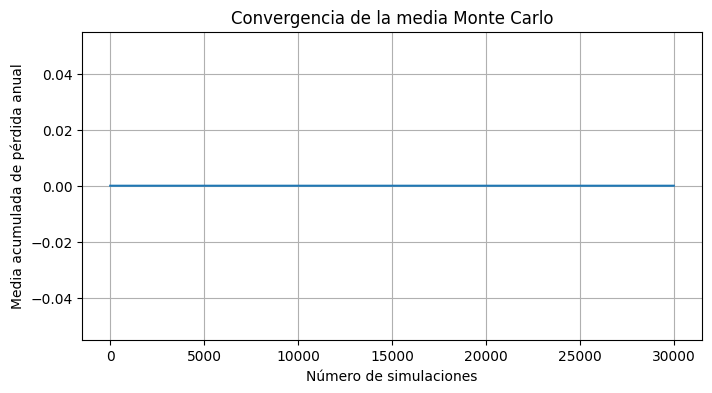

In [67]:
cum_mean = np.cumsum(losses) / np.arange(1, n_sim + 1)

plt.figure(figsize=(8, 4))
plt.plot(cum_mean)
plt.xlabel("Número de simulaciones")
plt.ylabel("Media acumulada de pérdida anual")
plt.title("Convergencia de la media Monte Carlo")
plt.grid(True)
plt.show()


In [68]:
for q in [0.90, 0.95, 0.99, 0.995]:
    print(f"P{int(q*100)} =", np.quantile(losses, q))



P90 = 0.0
P95 = 0.0
P99 = 0.0
P99 = 0.0


In [69]:
losses_pos = losses[losses > 0]

print("Proporción con pérdida:", len(losses_pos) / len(losses))

for q in [0.50, 0.75, 0.90, 0.95]:
    print(f"P{int(q*100)} | Loss > 0 =", np.quantile(losses_pos, q))


Proporción con pérdida: 0.0


IndexError: index -1 is out of bounds for axis 0 with size 0

In [71]:
quantiles = [0.90, 0.95, 0.99, 0.995]
step = 1000

rows = []

for i in range(step, len(losses) + 1, step):
    for q in quantiles:
        rows.append({
            "N": i,
            "Cuantil": f"P{q*100}",
            "Valor": np.quantile(losses[:i], q)
        })

df_incond = pd.DataFrame(rows)
df_incond


,N,Cuantil,Valor
0,1000,P90.0,0.0
1,1000,P95.0,0.0
2,1000,P99.0,0.0
3,1000,P99.5,0.0
4,2000,P90.0,0.0
...,...,...,...
115,29000,P99.5,0.0
116,30000,P90.0,0.0
117,30000,P95.0,0.0
118,30000,P99.0,0.0


In [72]:
mean_loss = losses.mean()
std_loss = losses.std(ddof=1)

mc_error = 1.96 * std_loss / np.sqrt(n_sim)
rel_error = mc_error / mean_loss

print(f"Media anual: {mean_loss:,.0f}")
print(f"Error Monte Carlo (95%): ±{mc_error:,.0f}")
print(f"Error relativo: {100*rel_error:.2f}%")


Media anual: 0
Error Monte Carlo (95%): ±0
Error relativo: nan%


/tmp/ipykernel_9034/285570122.py:5: RuntimeWarning: invalid value encountered in scalar divide
  rel_error = mc_error / mean_loss


In [73]:
half = n_sim // 2

stats_compare = pd.DataFrame({
    "Métrica": ["Media", "P95", "P99"],
    "Primera mitad": [
        losses[:half].mean(),
        np.quantile(losses[:half], 0.95),
        np.quantile(losses[:half], 0.99),
    ],
    "Total": [
        losses.mean(),
        np.quantile(losses, 0.95),
        np.quantile(losses, 0.99),
    ]
})

stats_compare["Variación %"] = (
    (stats_compare["Total"] - stats_compare["Primera mitad"])
    / stats_compare["Total"] * 100
)

stats_compare


,Métrica,Primera mitad,Total,Variación %
0,Media,0.0,0.0,NaN
1,P95,0.0,0.0,NaN
2,P99,0.0,0.0,NaN


In [74]:
threshold = np.quantile(losses, 0.99)
tail_losses = losses[losses >= threshold]

print(f"Simulaciones en cola 1%: {len(tail_losses)}")
print(f"Contribución de cola 1% a la media: "
      f"{tail_losses.mean() / mean_loss:.2f}x")


Simulaciones en cola 1%: 30000
Contribución de cola 1% a la media: nanx


/tmp/ipykernel_9034/2105325695.py:6: RuntimeWarning: invalid value encountered in scalar divide
  f"{tail_losses.mean() / mean_loss:.2f}x")


In [75]:
summary = pd.DataFrame({
    "Estadístico": ["Media", "P95", "P99", "P99.5"],
    "Valor": [
        mean_loss,
        np.quantile(losses, 0.95),
        np.quantile(losses, 0.99),
        np.quantile(losses, 0.995),
    ]
})

summary


,Estadístico,Valor
0,Media,0.0
1,P95,0.0
2,P99,0.0
3,P99.5,0.0


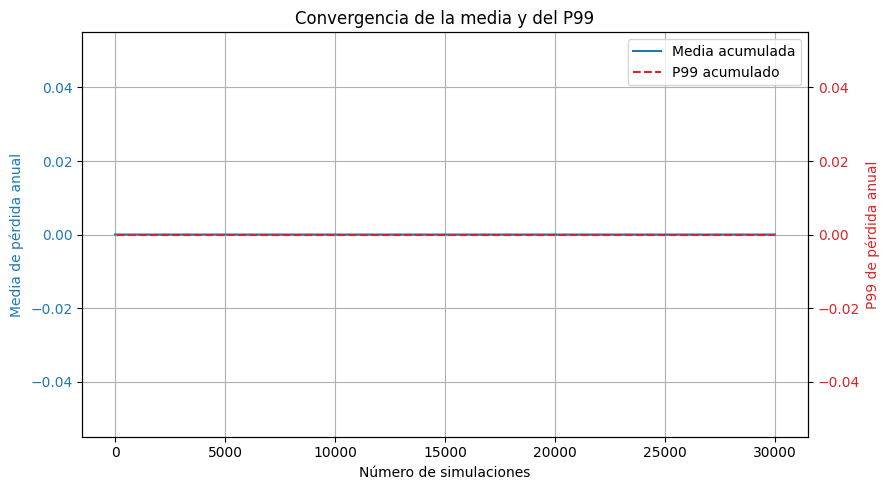

In [76]:
cum_mean = np.cumsum(losses) / np.arange(1, n_sim + 1)


step = 100

p99_vals = [
    np.quantile(losses[:i], 0.99)
    for i in range(step, n_sim + 1, step)
]

x_p99 = list(range(step, n_sim + 1, step))


fig, ax1 = plt.subplots(figsize=(9, 5))

# Media
ax1.plot(
    range(1, n_sim + 1),
    cum_mean,
    color="tab:blue",
    label="Media acumulada"
)
ax1.set_xlabel("Número de simulaciones")
ax1.set_ylabel("Media de pérdida anual", color="tab:blue")
ax1.tick_params(axis="y", labelcolor="tab:blue")
ax1.grid(True)

# Segundo eje: P99
ax2 = ax1.twinx()
ax2.plot(
    x_p99,
    p99_vals,
    color="tab:red",
    linestyle="--",
    label="P99 acumulado"
)
ax2.set_ylabel("P99 de pérdida anual", color="tab:red")
ax2.tick_params(axis="y", labelcolor="tab:red")

# Leyenda combinada
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc="best")

plt.title("Convergencia de la media y del P99")
plt.tight_layout()
plt.show()


In [ ]:
base_sim.to_csv("Cobertura_basica_simulaciones_por_poliza_vigente_con_retencion.csv", index=False)
base_annual.to_csv("Cobertura_basica_perdidas_anuales_vigente_con_retencion.csv", index=False)

##  3.2. Coberturas adicionales

In [ ]:
coberturas_adicionales["COB"].unique()

array(['Reembolso de Gastos Medicos', 'Perdidas Organicas A',
       'Perdidas Organicas B'], dtype=object)

In [ ]:
coberturas_adicionales["p_claim"] = coberturas_adicionales["COB"].map(PROB_BY_COB)

# Validación
if coberturas_adicionales["p_claim"].isna().any():
    raise ValueError("Hay coberturas en COB sin probabilidad asignada")


In [ ]:
results_by_cob = {}

for cob, p_claim in PROB_BY_COB.items():

    df_cob = coberturas_adicionales[coberturas_adicionales["COB"] == cob].copy()

    if df_cob.empty:
        print(f"⚠️ No hay pólizas para {cob}")
        continue

    sim_df, annual_df = simulate_losses_adicionales(
        df_cob,
        p_claim=p_claim,
        retention=1_500_000,
        n_sim=30_000,
        seed=2025
    )

    results_by_cob[cob] = {
        "simulations": sim_df,
        "annual_losses": annual_df
    }

    print(f"{cob}: {len(df_cob)} pólizas simuladas")


Reembolso de Gastos Medicos: 1530 pólizas simuladas
Perdidas Organicas A: 136 pólizas simuladas
Perdidas Organicas B: 806 pólizas simuladas


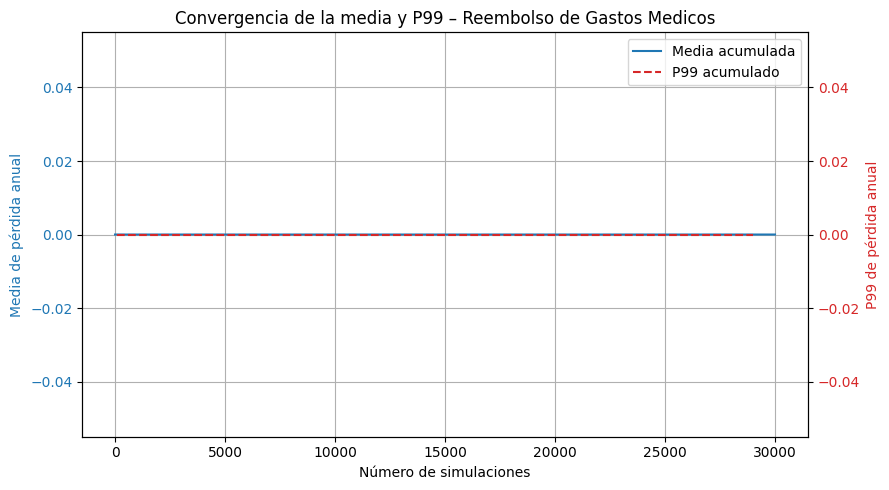

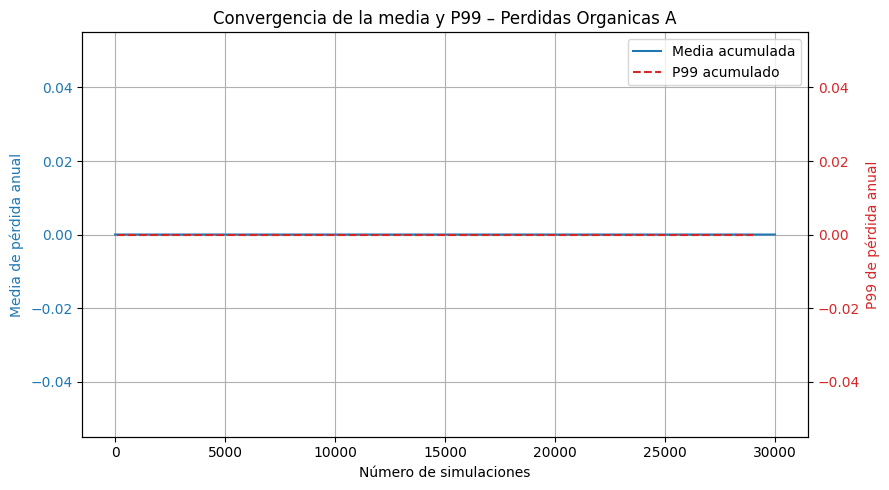

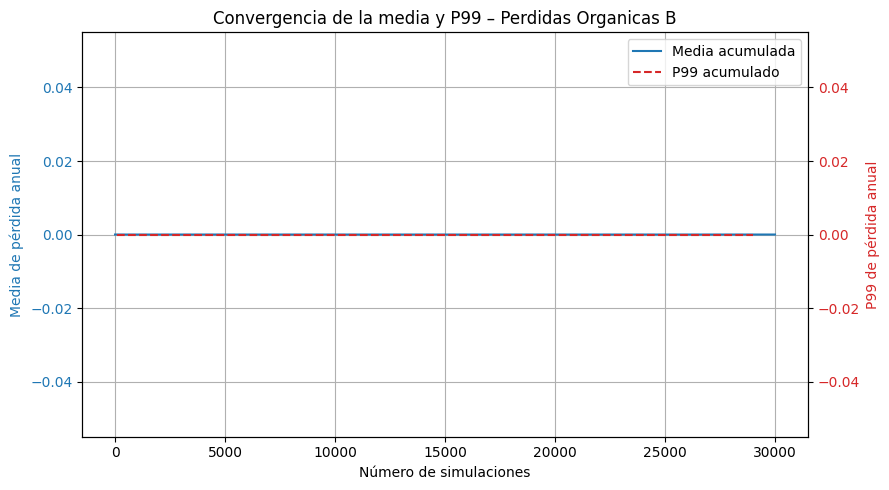

In [ ]:
for cob, res in results_by_cob.items():

    annual_losses = res["annual_losses"]["annual_loss"].values

    plot_convergence_mean_p99(
        losses=annual_losses,
        title=f"Convergencia de la media y P99 – {cob}"
    )


In [ ]:
for cob, res in results_by_cob.items():

    print(cob)
    print(res)


Reembolso de Gastos Medicos
{'simulations':               POL                          COB     FE_INI      F_FIN      SA  \
0    APCM00000032  Reembolso de Gastos Medicos 2025-04-01 2025-06-30  207500   
1    APCM00000032  Reembolso de Gastos Medicos 2025-04-01 2025-06-30  207500   
2    APCM00000032  Reembolso de Gastos Medicos 2025-04-01 2025-06-30  207500   
3    APCM00000032  Reembolso de Gastos Medicos 2025-04-01 2025-06-30  207500   
4    APCM00000032  Reembolso de Gastos Medicos 2025-04-01 2025-06-30  207500   
..            ...                          ...        ...        ...     ...   
654  APES00000020  Reembolso de Gastos Medicos 2025-09-01 2026-07-15  150000   
655  APES00000020  Reembolso de Gastos Medicos 2025-09-01 2026-07-15  150000   
656  APES00000020  Reembolso de Gastos Medicos 2025-09-01 2026-07-15  150000   
657  APES00000020  Reembolso de Gastos Medicos 2025-09-01 2026-07-15  150000   
658  APES00000020  Reembolso de Gastos Medicos 2025-09-01 2026-07-15  150000

In [ ]:
for cob, res in results_by_cob.items():
    name = cob.replace(" ", "_")

    res["simulations"].to_csv(
        f"Sheet2_{name}_simulaciones_por_poliza_con_retencion.csv",
        index=False
    )

    res["annual_losses"].to_csv(
        f"Sheet2_{name}_perdidas_anuales_con_retencion.csv",
        index=False
    )


# 4. Convergencia conjunta

In [ ]:
basic_annual = base_annual.rename(
    columns={"annual_loss": "loss_basic"}
)


In [ ]:
other_losses = []

for cob, res in results_by_cob.items():
    df = res["annual_losses"].copy()
    df = df.rename(columns={"annual_loss": f"loss_{cob}"})
    other_losses.append(df)


In [ ]:
other_annual = reduce(
    lambda left, right: pd.merge(
        left, right, on="simulation", how="outer"
    ),
    other_losses
)


In [ ]:
annual_all = pd.merge(
    basic_annual,
    other_annual,
    on="simulation",
    how="outer"
)


In [ ]:
loss_cols = [c for c in annual_all.columns if c.startswith("loss_")]

annual_all["loss_total"] = annual_all[loss_cols].sum(axis=1)


In [ ]:
annual_all[loss_cols + ["loss_total"]].describe()


,loss_basic,loss_Reembolso de Gastos Medicos,loss_Perdidas Organicas A,loss_Perdidas Organicas B,loss_total
count,3.000000e+04,30000.0,30000.0,3.000000e+04,3.000000e+04
mean,2.157000e+04,0.0,0.0,1.160250e+04,3.317250e+04
std,1.260657e+05,0.0,0.0,9.150418e+04,1.552617e+05
min,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00
25%,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00
50%,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00
75%,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00
max,1.950000e+06,0.0,0.0,1.950000e+06,1.950000e+06


In [ ]:
losses_total = (
    annual_all
    .sort_values("simulation")["loss_total"]
    .values
)


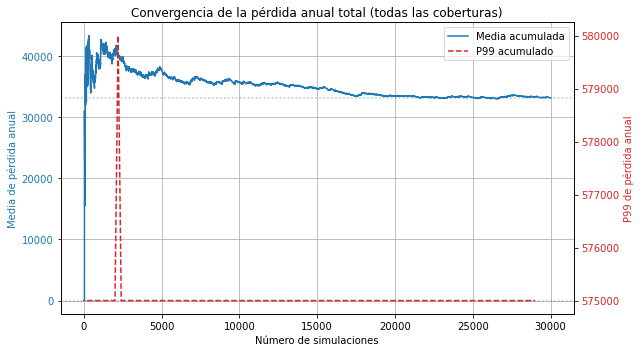

In [ ]:
plot_convergence_mean_p99_total(
    losses_total,
    title="Convergencia de la pérdida anual total (todas las coberturas)"
)
